# ACSIncome by state

Each state is a gossip node, as in FairFed (ACS PUMS 2018, 50 states plus Puerto Rico, 1,664,500 rows).
Target: income above $50,000. Protected attribute here: sex (FairFed used race, white or non-white).

Goals:
1. How the data splits across the 51 nodes
2. The male and female split in each state

In [ ]:
%pip install folktables
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from folktables import ACSDataSource, ACSIncome

  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached charset_normalizer-3.5.2-cp311-cp311-win_amd64.whl.metadata (47 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl.metadata (60 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached requests-2.34.2-py3-none-any.whl (73 kB)
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
    --------------------------------------- 0.2/8.3 MB 3.7 MB/s eta 0:00:03
   ---- ----------------------------------- 0.9/8.3 MB 9.6 MB/s eta 0:00:01
   ---------- ----------------------------- 2.2/8.3 MB 15.2 MB/s eta 0:00:01
   ------------------ --------------------- 3.9/8.3 MB 20.6 MB/s eta 0:00:01
   --------------------------- ------------ 5.6/8.3 MB 24.0 MB/s eta 0:00:01
   ----------------


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# 50 states plus Puerto Rico (no DC), the same 51 nodes as FairFed
STATES = ['AL', 'AK', 'AZ', 'AR', 'CA', 'CO', 'CT', 'DE', 'FL', 'GA', 'HI', 'ID', 'IL', 'IN', 'IA', 'KS', 'KY',
          'LA', 'ME', 'MD', 'MA', 'MI', 'MN', 'MS', 'MO', 'MT', 'NE', 'NV', 'NH', 'NJ', 'NM', 'NY', 'NC', 'ND',
          'OH', 'OK', 'OR', 'PA', 'RI', 'SC', 'SD', 'TN', 'TX', 'UT', 'VT', 'VA', 'WA', 'WV', 'WI', 'WY', 'PR']

# Downloads each state's 2018 person file into data/acs on the first run (large; cached afterwards)
source = ACSDataSource(survey_year='2018', horizon='1-Year', survey='person', root_dir='data/acs')
frames = []
for st in STATES:
    features, label, _ = ACSIncome.df_to_pandas(source.get_data(states=[st], download=True))
    frames.append(features.assign(ST=st, income_50k=label['PINCP'].astype(int)))
acs = pd.concat(frames, ignore_index=True)
acs['sex'] = acs['SEX'].map({1: 'Male', 2: 'Female'})
print(f'{len(acs):,} rows across {acs.ST.nunique()} nodes')  # FairFed reports 1,664,500

1,664,500 rows across 51 nodes


In [4]:
# One row per node: size, sex split, and the income gap in the data itself (women minus men)
by_state = acs.groupby('ST').agg(rows=('sex', 'size'), women=('sex', lambda s: (s == 'Female').sum()))
by_state['men'] = by_state['rows'] - by_state['women']
by_state['women %'] = (100 * by_state['women'] / by_state['rows']).round(1)
rates = acs.pivot_table(index='ST', columns='sex', values='income_50k', aggfunc='mean')
by_state['income gap'] = (rates['Female'] - rates['Male']).round(3)
by_state = by_state.sort_values('rows', ascending=False)
by_state

,rows,women,men,women %,income gap
ST,,,,,
CA,195665,92354,103311,47.2,-0.116
TX,135924,63695,72229,46.9,-0.155
NY,103021,50843,52178,49.4,-0.114
FL,98925,48103,50822,48.6,-0.140
PA,68308,32828,35480,48.1,-0.166
IL,67016,32420,34596,48.4,-0.173
OH,62135,29916,32219,48.1,-0.165
NC,52067,25320,26747,48.6,-0.155
GA,50915,24537,26378,48.2,-0.147


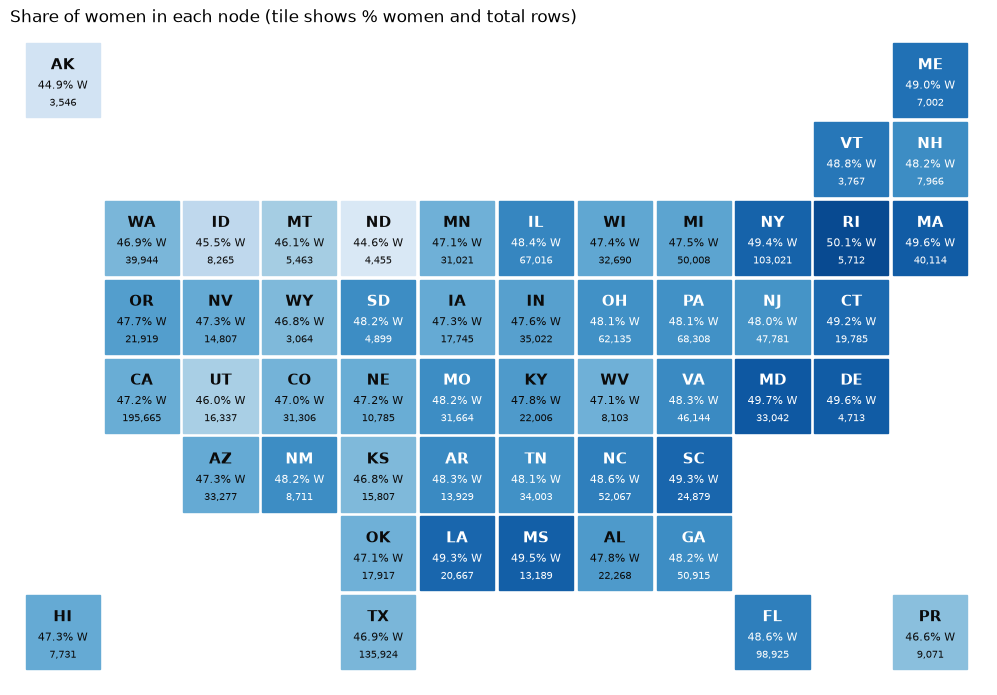

In [5]:
# Tile map: one equal-sized square per node, so small states stay visible
TILES = {'AK': (0, 0), 'ME': (0, 11), 'VT': (1, 10), 'NH': (1, 11),
         'WA': (2, 1), 'ID': (2, 2), 'MT': (2, 3), 'ND': (2, 4), 'MN': (2, 5), 'IL': (2, 6), 'WI': (2, 7),
         'MI': (2, 8), 'NY': (2, 9), 'RI': (2, 10), 'MA': (2, 11),
         'OR': (3, 1), 'NV': (3, 2), 'WY': (3, 3), 'SD': (3, 4), 'IA': (3, 5), 'IN': (3, 6), 'OH': (3, 7),
         'PA': (3, 8), 'NJ': (3, 9), 'CT': (3, 10),
         'CA': (4, 1), 'UT': (4, 2), 'CO': (4, 3), 'NE': (4, 4), 'MO': (4, 5), 'KY': (4, 6), 'WV': (4, 7),
         'VA': (4, 8), 'MD': (4, 9), 'DE': (4, 10),
         'AZ': (5, 2), 'NM': (5, 3), 'KS': (5, 4), 'AR': (5, 5), 'TN': (5, 6), 'NC': (5, 7), 'SC': (5, 8),
         'OK': (6, 4), 'LA': (6, 5), 'MS': (6, 6), 'AL': (6, 7), 'GA': (6, 8),
         'HI': (7, 0), 'TX': (7, 4), 'FL': (7, 9), 'PR': (7, 11)}

share = by_state['women %']
norm = plt.Normalize(share.min(), share.max())
fig, ax = plt.subplots(figsize=(13, 8.5))
for st, (r, c) in TILES.items():
    v = norm(share[st])
    ax.add_patch(Rectangle((c, -r), 0.94, 0.94, color=plt.cm.Blues(0.15 + 0.75 * v)))
    ink = 'white' if v > 0.6 else '#0b0b0b'
    ax.text(c + 0.47, -r + 0.66, st, ha='center', va='center', fontsize=11, fontweight='bold', color=ink)
    ax.text(c + 0.47, -r + 0.40, f"{share[st]:.1f}% W", ha='center', va='center', fontsize=8, color=ink)
    ax.text(c + 0.47, -r + 0.18, f"{by_state.loc[st, 'rows']:,}", ha='center', va='center', fontsize=7.5, color=ink)
ax.set_xlim(-0.2, 12.2)
ax.set_ylim(-7.2, 1.1)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title('Share of women in each node (tile shows % women and total rows)', loc='left')
plt.show()

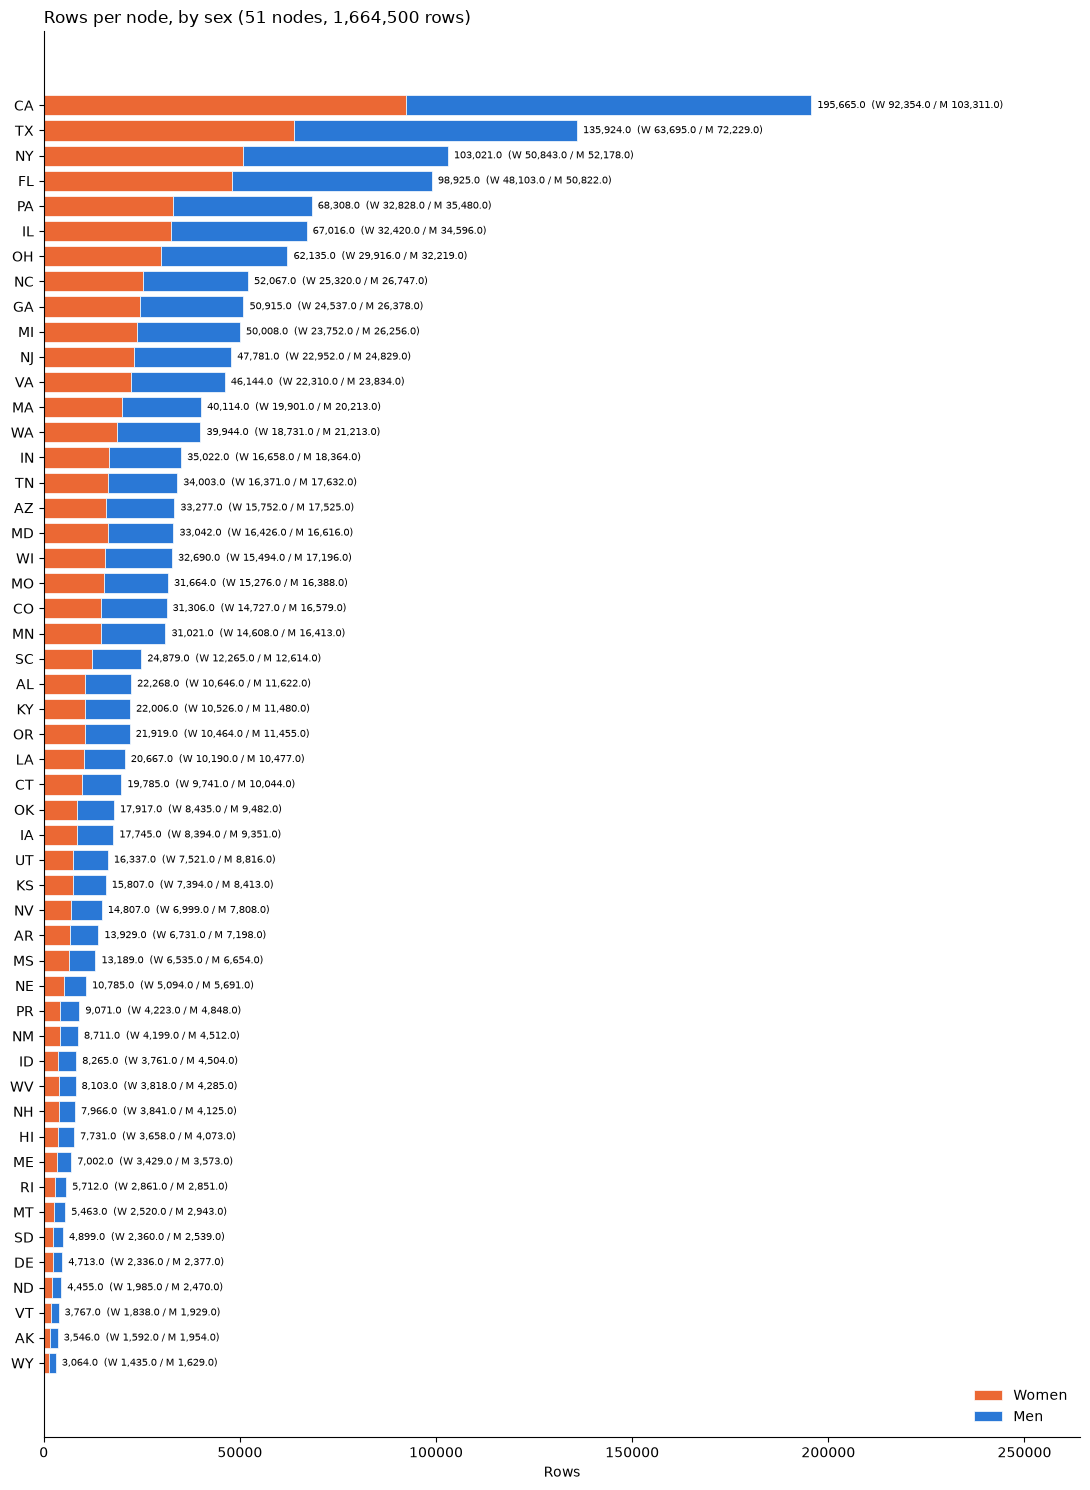

In [6]:
# Women and men per node, largest node at the top
order = by_state.sort_values('rows')
fig, ax = plt.subplots(figsize=(11, 15))
ax.barh(order.index, order['women'], color='#eb6834', edgecolor='white', linewidth=0.5, label='Women')
ax.barh(order.index, order['men'], left=order['women'], color='#2a78d6', edgecolor='white', linewidth=0.5, label='Men')
for st, row in order.iterrows():
    ax.text(row['rows'], st, f"  {row['rows']:,}  (W {row['women']:,} / M {row['men']:,})", va='center', fontsize=7.5)
ax.set_xlim(0, order['rows'].max() * 1.35)
ax.set_xlabel('Rows')
ax.set_title(f"Rows per node, by sex ({len(order)} nodes, {order['rows'].sum():,} rows)", loc='left')
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc='lower right')
plt.tight_layout()
plt.show()